In [48]:
# Alle Zeiten in Stunden. ACHTUNG: Platzhalterwerte (Annahmen), bitte durch eigene ersetzen!

# Seeweg: Marokko <-> Rotterdam
load_time_dme_sea = 12      # DME laden in Marokko
deload_time_dme_sea = 12    # DME löschen in Rotterdam

load_time_co2_sea = 12      # CO2 laden in Rotterdam
deload_time_co2_sea = 12    # CO2 löschen in Marokko

travel_time_sea = 100       # einfache Fahrt (Annahme)
annual_cycles_sea = 12      # Rundreisen pro Jahr

# Flussschifffahrt (aktuell nicht benötigt)
load_time_dme_river = None
deload_time_dme_river = None
load_time_co2_river = None
deload_time_co2_river = None
travel_time_river = None
annual_cycles_river = None


In [49]:
import numpy as np
import pandas as pd


def build_ship_profiles(
    load_dme, deload_dme, load_co2, deload_co2, travel_time, annual_cycles,
    n_hours=8760, snapshots=None,
):
    """0/1-Profile für eine Rundreise: DME Marokko -> Rotterdam, CO2 Rotterdam -> Marokko.

    Ablauf eines Zyklus (alle Schritte nacheinander):
      1. DME laden (Marokko)      -> 'dme_load_morocco'
      2. Fahrt nach Rotterdam     -> 'at_sea'
      3. DME löschen (Rotterdam)  -> 'dme_deload_rotterdam'
      4. CO2 laden (Rotterdam)    -> 'co2_load_rotterdam'
      5. Fahrt nach Marokko       -> 'at_sea'
      6. CO2 löschen (Marokko)    -> 'co2_deload_morocco'

    Der letzte Zyklus endet in der letzten Stunde des Jahres (mit dem CO2-Löschen).
    Von dort aus rückwärts sind die Zyklen im gleichen Abstand (n_hours / annual_cycles)
    über das Jahr verteilt. Es werden keine Zyklen abgeschnitten.
    """
    steps = [
        ("dme_load_morocco", load_dme),
        ("at_sea", travel_time),
        ("dme_deload_rotterdam", deload_dme),
        ("co2_load_rotterdam", load_co2),
        ("at_sea", travel_time),
        ("co2_deload_morocco", deload_co2),
    ]
    n_cycles = int(annual_cycles)
    cycle_len = sum(d for _, d in steps)
    spacing = n_hours / n_cycles
    if cycle_len > spacing:
        raise ValueError(
            f"Ein Zyklus dauert {cycle_len} h, bei {n_cycles} Zyklen/Jahr "
            f"stehen aber nur {spacing:.0f} h pro Zyklus zur Verfügung."
        )

    # Endstunden (inklusive): letzter Zyklus endet bei n_hours-1, die anderen im Abstand 'spacing' davor
    ends = np.round((n_hours - 1) - spacing * np.arange(n_cycles)[::-1]).astype(int)
    starts = ends - cycle_len + 1

    names = sorted({n for n, _ in steps})
    prof = {n: np.zeros(n_hours, dtype=int) for n in names}
    for t in starts:
        for name, dur in steps:
            prof[name][t:t + dur] = 1
            t += dur

    # Import-Profile: 1 von Jahresbeginn bis zur ersten Ankunft der Ladung (ohne die Löschstunden selbst)
    # -> in dieser Zeit muss Rotterdam DME bzw. Marokko CO2 von extern beziehen.
    prof["import_dme"] = (np.arange(n_hours) < np.argmax(prof["dme_deload_rotterdam"] == 1)).astype(int)
    prof["import_co2"] = (np.arange(n_hours) < np.argmax(prof["co2_deload_morocco"] == 1)).astype(int)
    if snapshots is None:
        snapshots = pd.date_range("2025-01-01", periods=n_hours, freq="h")
    return pd.DataFrame(prof, index=snapshots)


ship_sea = build_ship_profiles(
    load_dme=load_time_dme_sea,
    deload_dme=deload_time_dme_sea,
    load_co2=load_time_co2_sea,
    deload_co2=deload_time_co2_sea,
    travel_time=travel_time_sea,
    annual_cycles=annual_cycles_sea,
)
assert ship_sea["co2_deload_morocco"].iloc[-1] == 1  # Jahr endet mit CO2-Löschung
ship_sea.sum()  # Kontrolle: Betriebsstunden pro Profil


at_sea                  2400
co2_deload_morocco       144
co2_load_rotterdam       144
dme_deload_rotterdam     144
dme_load_morocco         144
import_dme               594
import_co2               718
dtype: int64

<Axes: >

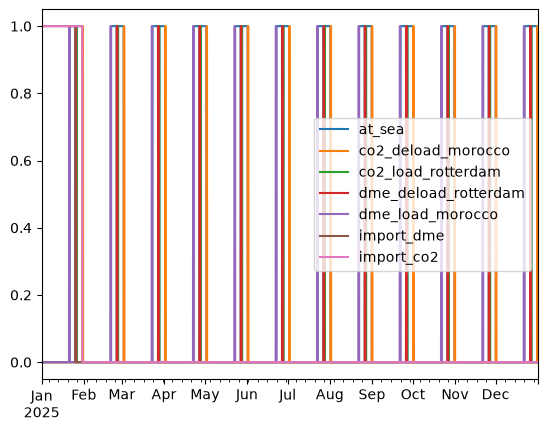

In [50]:
ship_sea.plot()

In [51]:
ship_sea.to_csv("Data/ship_profiles/ship_sea.csv")

In [52]:
n_years = 20
n_hours_year = len(ship_sea)

# Jahresprofil n_years-mal aneinanderhängen (jedes Jahr beginnt mit DME-Laden, endet mit CO2-Löschung,
# daher sind die Übergänge lückenlos). Jedes Jahr hat 8760 h, Schaltjahre werden ignoriert.
ship_sea_multi = pd.concat([ship_sea] * n_years, ignore_index=True)
ship_sea_multi.index = pd.date_range("2025-01-01", periods=len(ship_sea_multi), freq="h")
# Import-Profile gelten nur im ersten Jahr (danach ist Ladung unterwegs bzw. angekommen)
ship_sea_multi.loc[ship_sea_multi.index[n_hours_year:], ["import_dme", "import_co2"]] = 0
ship_sea_multi.shape  # (175200, 7)


(175200, 7)